In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# inlezen
df= pd.read_parquet('locatie_data\carport.parquet')

In [4]:
df.columns

Index(['timestamp', 'CO2EQ', 'CTYPE', 'ENAME', 'EONNAME', 'ETYPE', 'GNAME',
       'CTYPEC', 'ESTYPE', 'forecast.ENE', 'forecast.POW', 'ENE', 'POW', 'CO2',
       'CO2_EXP', 'CO2_IMP', 'ENE_EXP', 'ENE_IMP', 'COST', 'COST_EXP',
       'COST_IMP', 'ENE_CNT_EXP', 'ENE_CNT_IMP', 'PRICE'],
      dtype='object')

In [ ]:
# filteren op totaalverbruik in de kolom ENAME
totaalverbruik= df[df['ENAME']== 'totaalverbruik-e4393cd3dfdb']
totaalverbruik.head(5)


,timestamp,CO2EQ,CTYPE,ENAME,EONNAME,ETYPE,GNAME,CTYPEC,ESTYPE,forecast.ENE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
2975904,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,eiot-e4393cd3dfdb,powermeter,SERENE,consumption,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2975905,2024-03-08 01:05:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,eiot-e4393cd3dfdb,powermeter,SERENE,consumption,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2975906,2024-03-08 01:10:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,eiot-e4393cd3dfdb,powermeter,SERENE,consumption,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2975907,2024-03-08 01:15:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,eiot-e4393cd3dfdb,powermeter,SERENE,consumption,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2975908,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,eiot-e4393cd3dfdb,powermeter,SERENE,consumption,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


C:\Users\stijn\AppData\Local\Temp\ipykernel_16440\2961853235.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  totaalverbruik["timestamp"] = pd.to_datetime(totaalverbruik["timestamp"])


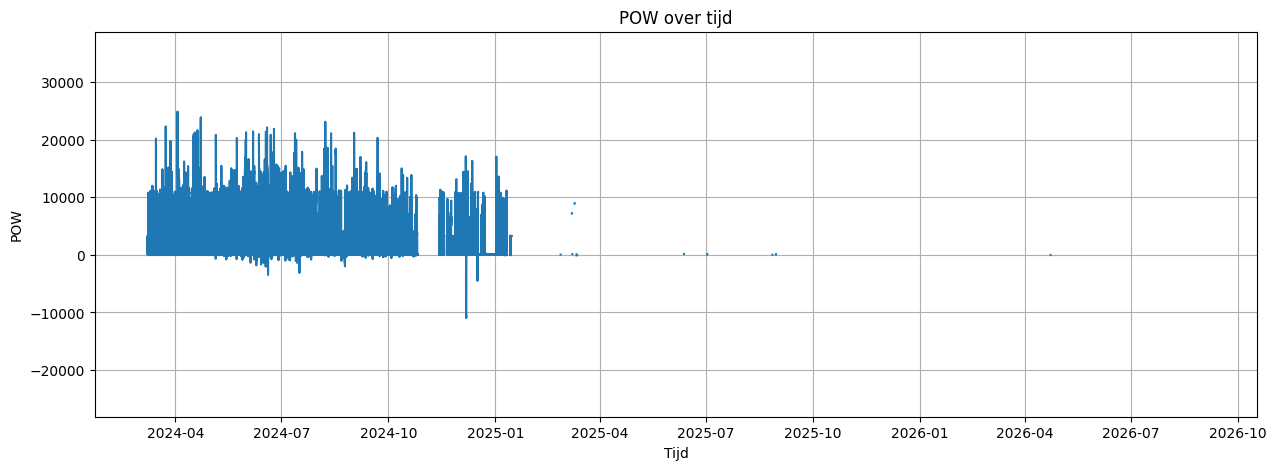

In [6]:
# Timestamp omzetten naar datetime
totaalverbruik["timestamp"] = pd.to_datetime(totaalverbruik["timestamp"])


# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(totaalverbruik["timestamp"], totaalverbruik["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [9]:
#  tijd filteren tussen waarin er wel een stuk data is 
df_zesmaanden = totaalverbruik[
    (totaalverbruik['timestamp'] > '2024-04-01') &
    (totaalverbruik['timestamp'] < '2024-10-01')
]

C:\Users\stijn\AppData\Local\Temp\ipykernel_16440\454585688.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_zesmaanden["timestamp"] = pd.to_datetime(df_zesmaanden["timestamp"])


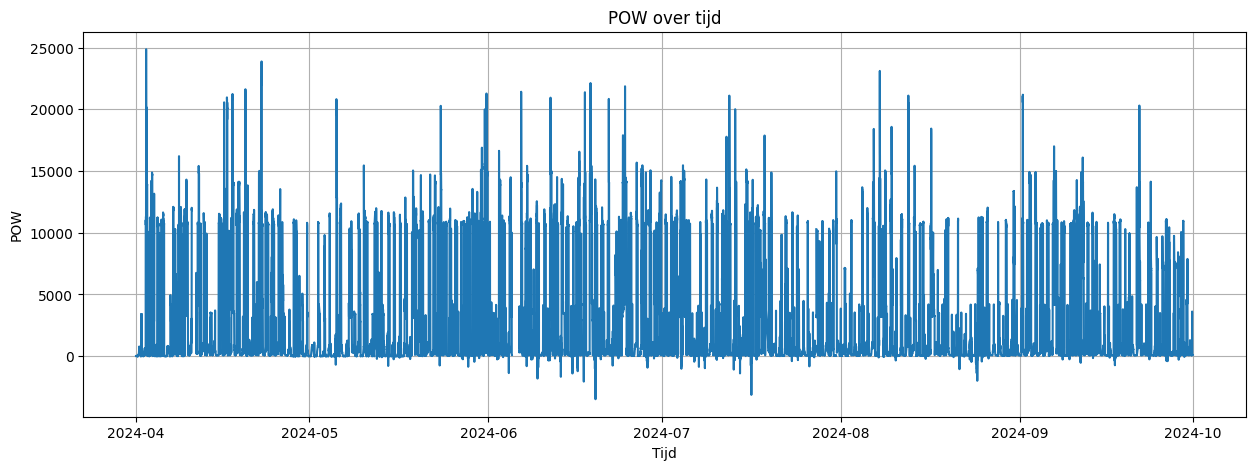

In [10]:
#  Timestamp omzetten naar datetime
df_zesmaanden["timestamp"] = pd.to_datetime(df_zesmaanden["timestamp"])

# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(df_zesmaanden["timestamp"], df_zesmaanden["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [13]:
# checken voor nul waarden POW
df_zesmaanden['POW'].isnull().sum()

np.int64(745)

In [14]:
df_zesmaanden_impute= df_zesmaanden.interpolate(method='linear')

C:\Users\stijn\AppData\Local\Temp\ipykernel_16440\944047296.py:1: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_zesmaanden_impute= df_zesmaanden.interpolate(method='linear')


In [16]:
# checken voor nul waarden POW
df_zesmaanden_impute['POW'].isnull().sum()

np.int64(0)

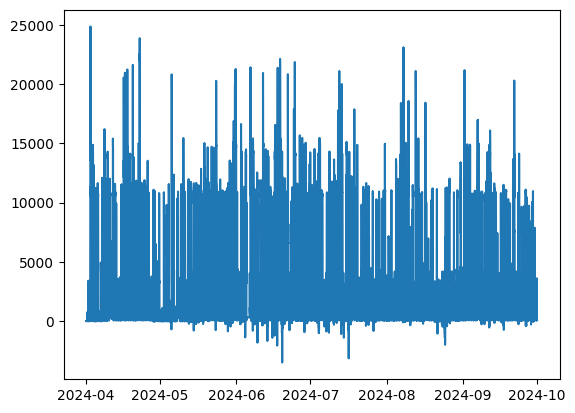

In [17]:
fig ,ax = plt.subplots()
plt.plot(df_zesmaanden_impute['timestamp'],df_zesmaanden_impute['POW'])
plt.show()

In [19]:
#  data tot parquet file
df_zesmaanden_impute.to_parquet("basic_impute_data_carport.gzip")